In [7]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__results__.html
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__notebook_source__.ipynb
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__notebook__.ipynb
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__output__.json
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/custom.css
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__results___files/__results___129_0.png
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__results___files/__results___61_0.png
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__results___files/__results___60_0.png
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__results___files/__results___132_1.png
/kaggle/input/notebooks/smitisinghal/skin-disease-classification/__results___files/__results___127_0.png
/kaggle/input/notebooks/smitisinghal/skin-disease-classificatio

In [9]:
import os
ROOT = "/kaggle/input"
for r, dirs, files in os.walk(ROOT):
    depth = r.replace(ROOT, "").count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(r) + f"/  ({len(files)} files)")
        for f in files[:3]: print("  " * (depth + 1) + f)

input/  (0 files)
  notebooks/  (0 files)
    smitisinghal/  (0 files)
      skin-disease-classification/  (5 files)
        __results__.html
        __notebook_source__.ipynb
        __notebook__.ipynb


In [1]:
!pip install -q timm

In [2]:
from pathlib import Path
import pandas as pd

BASE = Path("/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000")
paths = {p.stem: str(p) for p in BASE.rglob("*.jpg")}
meta = pd.read_csv(BASE / "HAM10000_metadata.csv")
meta["path"] = meta["image_id"].map(paths)

print("images found:", len(paths))
print("metadata rows:", len(meta))
print("rows with no image:", meta["path"].isna().sum())
print(meta["dx"].value_counts())

images found: 10015
metadata rows: 10015
rows with no image: 0
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import StratifiedGroupKFold

def carve(df, n_splits=6):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    rest_idx, part_idx = next(sgkf.split(df, df["dx"], groups=df["lesion_id"]))
    return df.iloc[rest_idx], df.iloc[part_idx]

trainval, test = carve(meta)
train, val = carve(trainval)

assert not set(train.lesion_id) & set(val.lesion_id)
assert not set(train.lesion_id) & set(test.lesion_id)
assert not set(val.lesion_id) & set(test.lesion_id)

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, len(d), d["dx"].value_counts().to_dict())

train 6970 {'nv': 4648, 'mel': 787, 'bkl': 775, 'bcc': 353, 'akiec': 232, 'vasc': 103, 'df': 72}
val 1395 {'nv': 953, 'bkl': 140, 'mel': 139, 'bcc': 76, 'akiec': 54, 'vasc': 17, 'df': 16}
test 1650 {'nv': 1104, 'mel': 187, 'bkl': 184, 'bcc': 85, 'akiec': 41, 'df': 27, 'vasc': 22}


In [4]:
import torch, timm, json, numpy as np
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

classes = sorted(meta["dx"].unique())      # ['akiec','bcc','bkl','df','mel','nv','vasc']
c2i = {c: i for i, c in enumerate(classes)}
json.dump(classes, open("/kaggle/working/classes.json", "w"))

def load(p): return Image.open(p).convert("RGB").resize((256, 256))
with ThreadPoolExecutor(4) as ex:
    imgs = list(ex.map(load, meta["path"]))
cache = dict(zip(meta["image_id"], imgs))

norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                      T.RandomVerticalFlip(), T.RandomRotation(30),
                      T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), norm])
eval_tf = T.Compose([T.CenterCrop(224), T.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, df, tf):
        self.ids, self.tf = df["image_id"].tolist(), tf
        self.y = df["dx"].map(c2i).tolist()
    def __len__(self): return len(self.ids)
    def __getitem__(self, i): return self.tf(cache[self.ids[i]]), self.y[i]

train_dl = DataLoader(DS(train, train_tf), batch_size=64, shuffle=True, num_workers=2)
val_dl   = DataLoader(DS(val, eval_tf), batch_size=64, num_workers=2)
test_dl  = DataLoader(DS(test, eval_tf), batch_size=64, num_workers=2)
print(classes)

['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [5]:
from sklearn.metrics import recall_score

dev = "cuda"
model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(classes)).to(dev)

counts = train["dx"].value_counts().reindex(classes).values
w = (1.0 / counts) ** 0.5
w = torch.tensor(w / w.sum() * len(classes), dtype=torch.float32).to(dev)
loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)

EPOCHS = 10
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

def predict(dl):
    model.eval(); L, Y = [], []
    with torch.no_grad():
        for x, y in dl:
            L.append(model(x.to(dev)).float().cpu()); Y.append(y)
    return torch.cat(L), torch.cat(Y)

best, history = 0, []
for ep in range(EPOCHS):
    model.train(); tot = 0
    for x, y in train_dl:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad()
        with torch.amp.autocast("cuda"):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * len(y)
    sched.step()
    vl, vy = predict(val_dl)
    pred = vl.argmax(1).numpy()
    bal = recall_score(vy, pred, average="macro")
    mel = recall_score(vy, pred, labels=[c2i["mel"]], average=None)[0]
    history.append((tot / len(train), bal, mel))
    print(f"epoch {ep+1}: loss {tot/len(train):.3f} | val balanced acc {bal:.3f} | melanoma recall {mel:.3f}")
    if bal > best:
        best = bal; torch.save(model.state_dict(), "/kaggle/working/model.pth")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1: loss 1.984 | val balanced acc 0.565 | melanoma recall 0.302
epoch 2: loss 1.254 | val balanced acc 0.590 | melanoma recall 0.554
epoch 3: loss 1.039 | val balanced acc 0.654 | melanoma recall 0.540
epoch 4: loss 0.946 | val balanced acc 0.629 | melanoma recall 0.525
epoch 5: loss 0.888 | val balanced acc 0.664 | melanoma recall 0.662
epoch 6: loss 0.813 | val balanced acc 0.670 | melanoma recall 0.698
epoch 7: loss 0.775 | val balanced acc 0.662 | melanoma recall 0.504
epoch 8: loss 0.744 | val balanced acc 0.663 | melanoma recall 0.547
epoch 9: loss 0.724 | val balanced acc 0.672 | melanoma recall 0.554
epoch 10: loss 0.716 | val balanced acc 0.662 | melanoma recall 0.568


Temperature: 0.813
              precision    recall  f1-score   support

       akiec      0.708     0.415     0.523        41
         bcc      0.733     0.741     0.737        85
         bkl      0.623     0.701     0.660       184
          df      0.615     0.593     0.604        27
         mel      0.500     0.567     0.531       187
          nv      0.918     0.888     0.903      1104
        vasc      0.714     0.909     0.800        22

    accuracy                          0.807      1650
   macro avg      0.687     0.688     0.680      1650
weighted avg      0.816     0.807     0.809      1650

Macro ROC-AUC: 0.9303124871659777


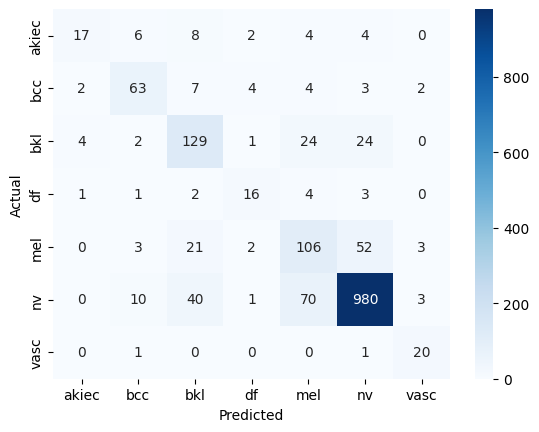

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns, matplotlib.pyplot as plt

model.load_state_dict(torch.load("/kaggle/working/model.pth")); model.eval()
val_logits, val_y = predict(val_dl)
test_logits, test_y = predict(test_dl)

logT = nn.Parameter(torch.zeros(1))
o = torch.optim.LBFGS([logT], lr=0.05, max_iter=100)
def closure():
    o.zero_grad(); l = F.cross_entropy(val_logits / logT.exp(), val_y); l.backward(); return l
o.step(closure)
TEMP = logT.exp().item(); print("Temperature:", round(TEMP, 3))

probs = F.softmax(test_logits / TEMP, 1).numpy()
pred = probs.argmax(1)
print(classification_report(test_y, pred, target_names=classes, digits=3))
print("Macro ROC-AUC:", roc_auc_score(test_y, probs, multi_class="ovr"))
sns.heatmap(confusion_matrix(test_y, pred), annot=True, fmt="d",
            xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [8]:
risky = [c2i[c] for c in ["mel", "bcc", "akiec"]]
val_p  = F.softmax(val_logits / TEMP, 1).numpy()
test_p = F.softmax(test_logits / TEMP, 1).numpy()
score = lambda p: p[:, risky].sum(1)
val_true  = np.isin(val_y.numpy(), risky)
test_true = np.isin(test_y.numpy(), risky)

THRESH = 0.10
for t in np.arange(0.90, 0.04, -0.01):
    if (score(val_p) >= t)[val_true].mean() >= 0.90:
        THRESH = round(float(t), 2); break

flag = score(test_p) >= THRESH
mel_true = test_y.numpy() == c2i["mel"]
print("Threshold:", THRESH)
print("Test sensitivity (risky lesions flagged):", round(flag[test_true].mean(), 3))
print("Test melanoma flagged:", round(flag[mel_true].mean(), 3))
print("Test specificity (benign not flagged):", round((~flag)[~test_true].mean(), 3))

json.dump({"temperature": TEMP, "flag_threshold": THRESH},
          open("/kaggle/working/config.json", "w"))

Threshold: 0.09
Test sensitivity (risky lesions flagged): 0.917
Test melanoma flagged: 0.914
Test specificity (benign not flagged): 0.68


In [9]:
import shutil, os
from IPython.display import FileLink

os.makedirs("/kaggle/working/demo_images", exist_ok=True)
for c in classes:
    for r in test[test.dx == c].head(2).itertuples():
        shutil.copy(r.path, f"/kaggle/working/demo_images/{c}_{r.image_id}.jpg")
shutil.make_archive("/kaggle/working/demo_images", "zip", "/kaggle/working/demo_images")

print(os.listdir("/kaggle/working"))
for f in ["model.pth", "classes.json", "config.json", "demo_images.zip"]:
    display(FileLink(f"/kaggle/working/{f}") if False else FileLink(f))

['model.pth', 'demo_images', '.virtual_documents', 'config.json', 'classes.json', 'demo_images.zip']


/kaggle/working/model.pth

/kaggle/working/classes.json

/kaggle/working/config.json

/kaggle/working/demo_images.zip

In [10]:
import json, os, torch

D = "/kaggle/working"

print("=== classes.json ===")
print(open(f"{D}/classes.json").read())

print("\n=== config.json ===")
print(open(f"{D}/config.json").read())

print("\n=== model.pth ===")
print("File size:", round(os.path.getsize(f"{D}/model.pth") / 1e6, 1), "MB")
sd = torch.load(f"{D}/model.pth", map_location="cpu")
print("Number of weight tensors:", len(sd))
print("Total parameters:", f"{sum(v.numel() for v in sd.values()):,}")
print("\nFirst 5 tensors (name, shape):")
for k in list(sd)[:5]:
    print(" ", k, tuple(sd[k].shape))
print("\nLast layer (the 7-class output):")
last = [k for k in sd if k.startswith("classifier")]
for k in last:
    print(" ", k, tuple(sd[k].shape))

=== classes.json ===
["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

=== config.json ===
{"temperature": 0.812843918800354, "flag_threshold": 0.09}

=== model.pth ===
File size: 16.3 MB
Number of weight tensors: 360
Total parameters: 4,058,580

First 5 tensors (name, shape):
  conv_stem.weight (32, 3, 3, 3)
  bn1.weight (32,)
  bn1.bias (32,)
  bn1.running_mean (32,)
  bn1.running_var (32,)

Last layer (the 7-class output):
  classifier.weight (7, 1280)
  classifier.bias (7,)
